In [ ]:
#09 RESULTS: Tm BASELINE MODEL
#EVERYTHING IS READ FROM THE FILES WRITTEN BY run_baseline.py (NOTHING IS RETRAINED HERE).

import numpy as np                                                         #LIBRARY FOR NUMERICAL OPERATIONS
import pandas as pd                                                        #LIBRARY FOR DATA TABLES
import matplotlib.pyplot as plt                                            #LIBRARY FOR PLOTTING
from pathlib import Path                                                   #LIBRARY FOR FILE PATHS
from scipy import stats                                                    #LIBRARY FOR CORRELATIONS
from rdkit import Chem, RDLogger                                           #LIBRARY FOR FUNCTIONAL GROUP CLASSIFICATION
from matplotlib.patches import Patch                                       #LEGEND ENTRIES FOR THE SHADED BANDS
RDLogger.DisableLog("rdApp.*")                                             #SILENCES RDKIT WARNINGS

DS = "Tm"                                                              #DATASET: "dHfus" OR "Tm"
CFG = {
    "dHfus": dict(name="ΔHfus", unit="kcal/mol", n_test=450,  bands=(1.5, 3.0),  edges=[0, 1.5, 3, 5, 10, np.inf],  cum=[1.5, 3, 5],   near_zero=0.5),
    "Tm":    dict(name="Tm",    unit="K",        n_test=1000, bands=(25.0, 50.0), edges=[0, 25, 50, 100, np.inf],    cum=[25, 50, 100], near_zero=50.0),
}[DS]                                                                      #BANDS MATCH THE PARITY BANDS USED IN SECTION 5.8
NAME, UNIT = CFG["name"], CFG["unit"]
print("DATASET:", DS, "| EXPECTED TEST SET SIZE:", CFG["n_test"])

DATASET: Tm | EXPECTED TEST SET SIZE: 1000


In [ ]:
#LOAD THE SEED 0 TEST PREDICTIONS AND CHECK THEY ARE THE CURRENT ONES
pred = pd.read_csv(f"{DS}_baseline_predictions.csv")                       #SEED 0 TEST PREDICTIONS
pred["residual"] = pred["y_pred"] - pred["y_true"]                         #PREDICTED MINUS TRUE
pred["abs_error"] = pred["residual"].abs()                                 #ABSOLUTE ERROR
pred["rel_error_pct"] = 100 * pred["abs_error"] / pred["y_true"].abs()     #RELATIVE ERROR IN PERCENT
seeds = pd.read_csv(f"baseline_seeds_{DS}.csv")                            #10-SEED RESULTS
s0 = seeds[seeds["seed"] == 0].iloc[0]                                     #SEED 0 ROW, TO CROSS-CHECK THE PREDICTIONS FILE

mae = pred["abs_error"].mean()
rmse = np.sqrt((pred["abs_error"] ** 2).mean())
print(f"PREDICTIONS FILE: {len(pred)} MOLECULES | MAE = {mae:.4f} | RMSE = {rmse:.4f}")
print(f"SEED 0 IN baseline_seeds_{DS}.csv: MAE = {s0['test_mae']:.4f} | RMSE = {s0['test_rmse']:.4f}")
ok_n = len(pred) == CFG["n_test"]
ok_mae = np.isclose(mae, s0["test_mae"], rtol=2e-3)
if not (ok_n and ok_mae):                                                  #STOPS HERE IF THE PREDICTIONS FILE IS OLD (WRONG SIZE OR WRONG ERROR)
    raise RuntimeError(f"STALE PREDICTIONS FILE: SIZE OK = {ok_n}, MAE MATCHES SEED 0 = {ok_mae}. RERUN run_baseline.py (OR RESTORE THE NEW FILE) BEFORE CONTINUING")
print("CHECK PASSED: THE PREDICTIONS FILE IS THE CURRENT SEED 0 BASELINE")

PREDICTIONS FILE: 1000 MOLECULES | MAE = 32.0391 | RMSE = 42.4299
SEED 0 IN baseline_seeds_Tm.csv: MAE = 32.0391 | RMSE = 42.4299
CHECK PASSED: THE PREDICTIONS FILE IS THE CURRENT SEED 0 BASELINE


In [3]:
#10-SEED SUMMARY OF THE BASELINE (THE NUMBERS QUOTED IN THE REPORT)
cols = ["test_mae", "test_rmse", "epochs"]
summary = seeds[cols].agg(["mean", "std", "median", "min", "max"]).T.round(3)   #MEAN AND SPREAD OVER SEEDS
print(summary)
print(seeds[["seed"] + cols].round(3).to_string(index=False))              #ONE ROW PER SEED
print("RMSE/MAE RATIO, MEAN OVER SEEDS:", round((seeds["test_rmse"] / seeds["test_mae"]).mean(), 2))   #LARGE RATIO = A FEW LARGE ERRORS
print("SEEDS THAT REACHED THE 50 EPOCH LIMIT:", int((seeds["epochs"] >= 50).sum()), "OF", len(seeds))
summary.to_csv(f"{DS}_baseline_summary.csv")

             mean    std  median     min     max
test_mae   32.665  0.781  32.538  31.507  33.991
test_rmse  42.633  1.115  42.529  40.790  44.836
epochs     41.700  8.706  45.000  23.000  50.000
 seed  test_mae  test_rmse  epochs
    0    32.039     42.430      45
    1    32.592     42.578      50
    2    31.888     41.371      31
    3    33.287     43.419      45
    4    33.088     42.734      48
    5    31.507     40.790      41
    6    32.300     42.316      45
    7    32.483     42.480      50
    8    33.991     44.836      23
    9    33.472     43.376      39
RMSE/MAE RATIO, MEAN OVER SEEDS: 1.31
SEEDS THAT REACHED THE 50 EPOCH LIMIT: 2 OF 10


LOSS CURVE EPOCHS: 46 | SEED 0 TRAINED FOR 45 EPOCHS (THESE SHOULD AGREE IF THE CURVE IS SEED 0)


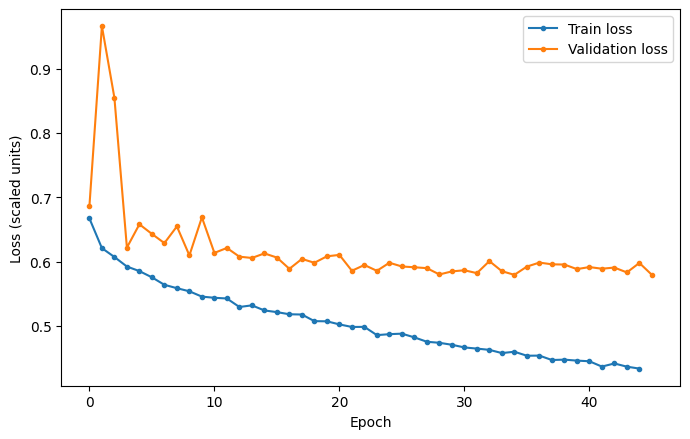

        Split    MAE   RMSE    N
        Train 25.384 35.335 8000
Test (seed 0) 32.039 42.430 1000
TEST MAE IS 26.2% HIGHER THAN TRAIN MAE


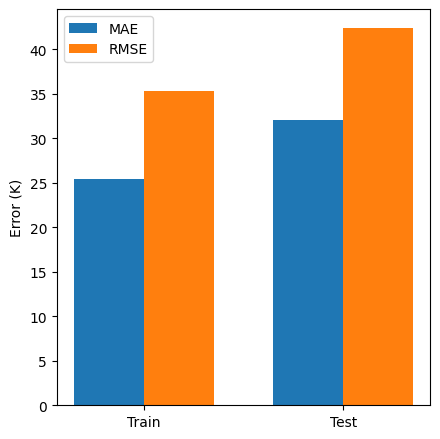

In [4]:
#TRAINING DIAGNOSTICS: LOSS CURVES AND TRAIN VS TEST ERROR (OPTIONAL FILES, SKIPPED IF NOT FOUND)
LOSS_FILE = Path(f"{DS}_baseline_loss_curve.csv")
if LOSS_FILE.exists():
    lc = pd.read_csv(LOSS_FILE)
    em = lc.groupby("epoch")[["train_loss_epoch", "val_loss"]].mean()      #MEAN PER EPOCH
    print("LOSS CURVE EPOCHS:", int(em.index.max()) + 1, "| SEED 0 TRAINED FOR", int(s0["epochs"]), "EPOCHS (THESE SHOULD AGREE IF THE CURVE IS SEED 0)")
    fig, ax = plt.subplots(figsize=(7, 4.5))
    ax.plot(em.index, em["train_loss_epoch"], label="Train loss", marker="o", markersize=3)
    ax.plot(em.index, em["val_loss"], label="Validation loss", marker="o", markersize=3)
    ax.set_xlabel("Epoch"); ax.set_ylabel("Loss (scaled units)"); ax.legend()
    plt.tight_layout(); plt.savefig(f"plots_{DS}_loss_curves.png", dpi=150); plt.show()
else:
    print("SKIPPED LOSS CURVE: FILE NOT FOUND:", LOSS_FILE)

TRAIN_FILE = Path(f"{DS}_baseline_train_predictions.csv")
if TRAIN_FILE.exists():
    tr = pd.read_csv(TRAIN_FILE)
    tr_abs = (tr["y_pred"] - tr["y_true"]).abs()                           #TRAINING SET ABSOLUTE ERRORS
    tr_mae, tr_rmse = tr_abs.mean(), np.sqrt((tr_abs ** 2).mean())
    cmp_ = pd.DataFrame({"Split": ["Train", "Test (seed 0)"], "MAE": [tr_mae, mae], "RMSE": [tr_rmse, rmse], "N": [len(tr), len(pred)]})
    print(cmp_.round(3).to_string(index=False))
    print(f"TEST MAE IS {(mae - tr_mae) / tr_mae * 100:.1f}% HIGHER THAN TRAIN MAE")
    fig, ax = plt.subplots(figsize=(4.5, 4.5))
    x = np.arange(2)
    ax.bar(x - 0.175, cmp_["MAE"], 0.35, label="MAE"); ax.bar(x + 0.175, cmp_["RMSE"], 0.35, label="RMSE")
    ax.set_xticks(x); ax.set_xticklabels(["Train", "Test"]); ax.set_ylabel(f"Error ({UNIT})"); ax.legend()
    plt.tight_layout(); plt.savefig(f"plots_{DS}_train_vs_test.png", dpi=150); plt.show()
else:
    print("SKIPPED TRAIN VS TEST: FILE NOT FOUND:", TRAIN_FILE)

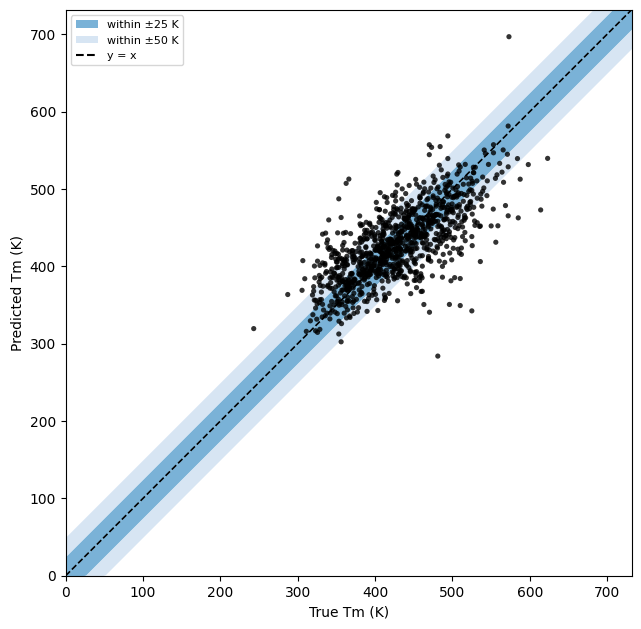

WITHIN ±25 K: 50.4%
WITHIN ±50 K: 78.6%

FIVE LARGEST ERRORS:
                                  smiles  y_true  y_pred  residual
                          CCn1ncc(C)c1Cl  481.15  283.97   -197.18
        COc1cccc(C2NCCCC2NCc2ccccc2OC)c1  525.15  342.41   -182.74
     COc1c(C)cc(Br)cc1CNC1CCCNC1c1ccccc1  510.15  349.30   -160.85
Cc1nccc(C(=O)O)c1-c1nc(-c2ccc(Cl)cc2)cs1  366.15  512.83    146.68
                         C[N+]1(C)CCCCC1  496.15  350.74   -145.41


In [5]:
#PARITY PLOT WITH ERROR BANDS, AND THE SHARE OF MOLECULES INSIDE EACH BAND
b1, b2 = CFG["bands"]
lim = max(pred["y_true"].max(), pred["y_pred"].max()) * 1.05
xl = np.linspace(0, lim, 200)
fig, ax = plt.subplots(figsize=(6.5, 6.5))
for lo, hi, c in [(0, b1, "#4292c6"), (b1, b2, "#c6dbef")]:                #DARK = WITHIN b1, LIGHT = BETWEEN b1 AND b2
    ax.fill_between(xl, xl + lo, xl + hi, color=c, alpha=0.7, linewidth=0)
    ax.fill_between(xl, np.maximum(xl - hi, 0), np.maximum(xl - lo, 0), color=c, alpha=0.7, linewidth=0)
ax.plot(xl, xl, "k--", linewidth=1.2, zorder=5)
ax.scatter(pred["y_true"], pred["y_pred"], color="black", s=14, alpha=0.8, zorder=6, edgecolor="none")
ax.legend(handles=[Patch(facecolor="#4292c6", alpha=0.7, label=f"within ±{b1:g} {UNIT}"),
                   Patch(facecolor="#c6dbef", alpha=0.7, label=f"within ±{b2:g} {UNIT}"),
                   plt.Line2D([0], [0], color="black", linestyle="--", label="y = x")], loc="upper left", fontsize=8)
ax.set_xlim(0, lim); ax.set_ylim(0, lim); ax.set_aspect("equal", adjustable="box")
ax.set_xlabel(f"True {NAME} ({UNIT})"); ax.set_ylabel(f"Predicted {NAME} ({UNIT})")
plt.tight_layout(); plt.savefig(f"plots_{DS}_parity_bands.png", dpi=150); plt.show()

for b in (b1, b2):
    print(f"WITHIN ±{b:g} {UNIT}: {100 * (pred['abs_error'] <= b).mean():.1f}%")
print("\nFIVE LARGEST ERRORS:")
big = pred.nlargest(5, "abs_error")[["smiles", "y_true", "y_pred", "residual"]].copy()
big["smiles"] = big["smiles"].str.slice(0, 45)
print(big.round(2).to_string(index=False))                                 #NEGATIVE RESIDUAL = UNDERPREDICTION

Band (K)  Count  Percentage  Cumulative %
    0-25    504        50.4          50.4
   25-50    282        28.2          78.6
  50-100    188        18.8          97.4
    >100     26         2.6         100.0

EXCLUDED FROM RELATIVE ERROR: 0 MOLECULES WITH |TRUE VALUE| < 50 K
ABSOLUTE ERROR: MEAN 32.039 | MEDIAN 24.419 | 90TH PCT 69.297 | 95TH PCT 83.657 | MAX 197.181
RELATIVE ERROR: MEAN 7.6% | MEDIAN 5.7%


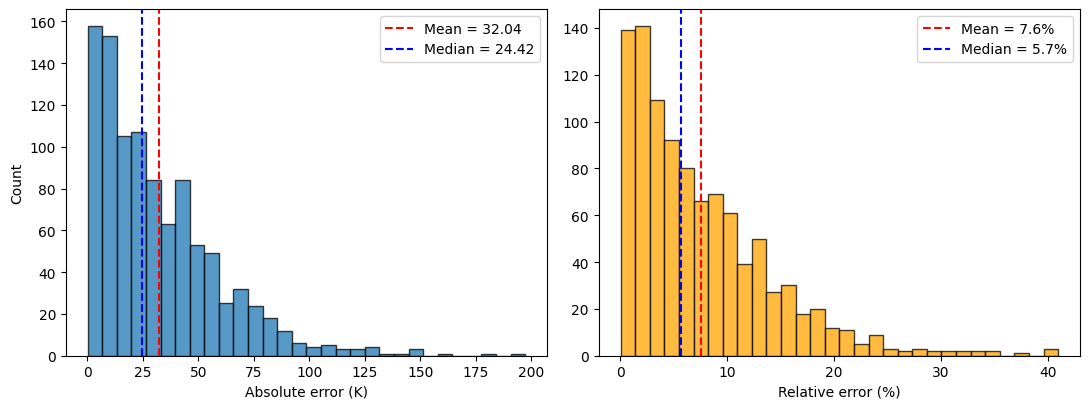

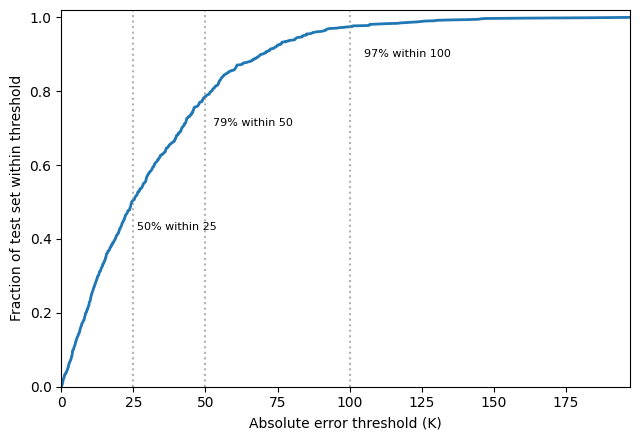

In [6]:
#ERROR BAND TABLE, CUMULATIVE ERRORS AND ERROR STATISTICS
edges = CFG["edges"]
labels = [f"{lo:g}-{hi:g}" if np.isfinite(hi) else f">{lo:g}" for lo, hi in zip(edges[:-1], edges[1:])]
pred["error_band"] = pd.cut(pred["abs_error"], bins=edges, labels=labels, right=True, include_lowest=True)
counts = pred["error_band"].value_counts().reindex(labels)
band_tab = pd.DataFrame({f"Band ({UNIT})": labels, "Count": counts.values,
                         "Percentage": (counts / len(pred) * 100).round(1).values,
                         "Cumulative %": (counts.cumsum() / len(pred) * 100).round(1).values})
print(band_tab.to_string(index=False))
band_tab.to_csv(f"{DS}_baseline_error_bands.csv", index=False)

nz = pred["y_true"].abs() < CFG["near_zero"]                               #NEAR-ZERO TRUE VALUES GIVE MEANINGLESS RELATIVE ERRORS
rel = pred.loc[~nz, "rel_error_pct"]
print(f"\nEXCLUDED FROM RELATIVE ERROR: {int(nz.sum())} MOLECULES WITH |TRUE VALUE| < {CFG['near_zero']:g} {UNIT}")
print(f"ABSOLUTE ERROR: MEAN {mae:.3f} | MEDIAN {pred['abs_error'].median():.3f} | 90TH PCT {pred['abs_error'].quantile(0.9):.3f} | 95TH PCT {pred['abs_error'].quantile(0.95):.3f} | MAX {pred['abs_error'].max():.3f}")
print(f"RELATIVE ERROR: MEAN {rel.mean():.1f}% | MEDIAN {rel.median():.1f}%")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
axes[0].hist(pred["abs_error"], bins=30, edgecolor="black", alpha=0.75)
axes[0].axvline(mae, color="red", linestyle="--", label=f"Mean = {mae:.2f}")
axes[0].axvline(pred["abs_error"].median(), color="blue", linestyle="--", label=f"Median = {pred['abs_error'].median():.2f}")
axes[0].set_xlabel(f"Absolute error ({UNIT})"); axes[0].set_ylabel("Count"); axes[0].legend()
axes[1].hist(rel, bins=30, edgecolor="black", alpha=0.75, color="orange")
axes[1].axvline(rel.mean(), color="red", linestyle="--", label=f"Mean = {rel.mean():.1f}%")
axes[1].axvline(rel.median(), color="blue", linestyle="--", label=f"Median = {rel.median():.1f}%")
axes[1].set_xlabel("Relative error (%)"); axes[1].legend()
plt.tight_layout(); plt.savefig(f"plots_{DS}_error_distributions.png", dpi=150); plt.show()

xs = np.sort(pred["abs_error"].values)
fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.plot(xs, np.arange(1, len(xs) + 1) / len(xs), linewidth=2)
for t in CFG["cum"]:
    f = (pred["abs_error"] <= t).mean()
    ax.axvline(t, color="gray", linestyle=":", alpha=0.6)
    ax.annotate(f"{f:.0%} within {t:g}", xy=(t, f), xytext=(t * 1.05, f - 0.08), fontsize=8)
ax.set_xlabel(f"Absolute error threshold ({UNIT})"); ax.set_ylabel("Fraction of test set within threshold")
ax.set_xlim(0, xs.max()); ax.set_ylim(0, 1.02)
plt.tight_layout(); plt.savefig(f"plots_{DS}_cumulative_error.png", dpi=150); plt.show()

RESIDUAL TREND SLOPE: -0.428 | CORRELATION BETWEEN TRUE VALUE AND RESIDUAL: -0.588 | MEAN RESIDUAL: -0.167 | SD: 42.451
              count    mean
y_true                     
Low third       336  25.886
Middle third    331   1.965
High third      333 -28.572
y_true
Low third       32.779
Middle third    24.602
High third      38.685
Name: MAE per third, dtype: float64


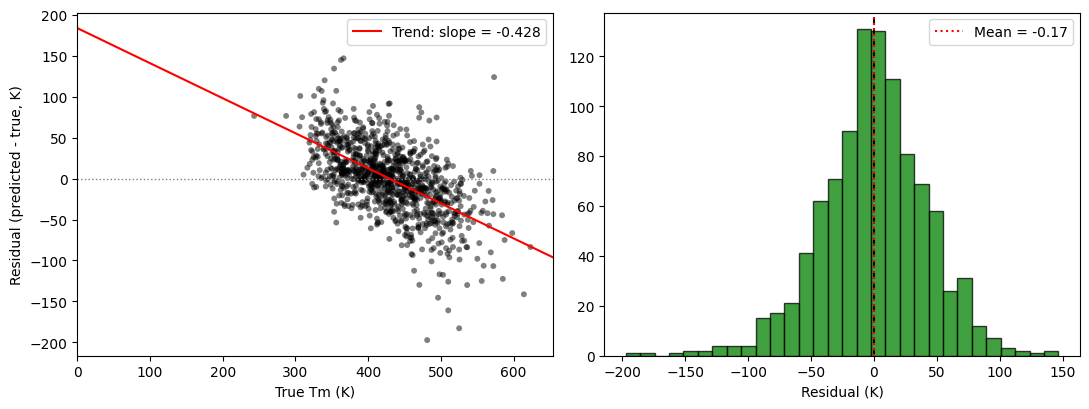

In [7]:
#RESIDUALS: IS THERE A BIAS WITH THE TRUE VALUE (REGRESSION TO THE MEAN)?
slope, intercept = np.polyfit(pred["y_true"], pred["residual"], 1)          #NEGATIVE SLOPE = UNDERPREDICTS HIGH VALUES, OVERPREDICTS LOW VALUES
corr = np.corrcoef(pred["y_true"], pred["residual"])[0, 1]
print(f"RESIDUAL TREND SLOPE: {slope:.3f} | CORRELATION BETWEEN TRUE VALUE AND RESIDUAL: {corr:.3f} | MEAN RESIDUAL: {pred['residual'].mean():.3f} | SD: {pred['residual'].std():.3f}")
tert = pd.qcut(pred["y_true"], 3, labels=["Low third", "Middle third", "High third"])
print(pred.groupby(tert, observed=True)["residual"].agg(["count", "mean"]).round(3))   #MEAN RESIDUAL PER THIRD OF THE TRUE VALUES
print(pred.groupby(tert, observed=True)["abs_error"].mean().round(3).rename("MAE per third"))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
axes[0].scatter(pred["y_true"], pred["residual"], alpha=0.5, s=18, color="black", edgecolor="none")
axes[0].axhline(0, color="gray", linestyle=":", linewidth=1)
tx = np.array([0, pred["y_true"].max() * 1.05])
axes[0].plot(tx, slope * tx + intercept, color="red", linewidth=1.5, label=f"Trend: slope = {slope:.3f}")
axes[0].set_xlim(0, tx[1]); axes[0].set_xlabel(f"True {NAME} ({UNIT})"); axes[0].set_ylabel(f"Residual (predicted - true, {UNIT})"); axes[0].legend()
axes[1].hist(pred["residual"], bins=30, edgecolor="black", alpha=0.75, color="green")
axes[1].axvline(0, color="black", linestyle="--")
axes[1].axvline(pred["residual"].mean(), color="red", linestyle=":", label=f"Mean = {pred['residual'].mean():.2f}")
axes[1].set_xlabel(f"Residual ({UNIT})"); axes[1].legend()
plt.tight_layout(); plt.savefig(f"plots_{DS}_residuals.png", dpi=150); plt.show()

                    n     mae  median_ae  mean_residual
functional_class                                       
Alkane/Other       27  48.032     33.800        -10.592
Amine             206  36.087     28.088         -5.842
Alkene              1  35.376     35.376         35.376
Alcohol            43  32.992     24.636          3.790
Ether              65  30.938     24.074          5.864
Carboxylic acid   127  30.548     21.006          6.255
Amide             279  30.405     25.495          0.913
Ester             150  30.156     23.703         -6.534
Aromatic          102  28.994     22.059          6.609

PER-CLASS RESIDUAL TREND SLOPE:
  Alcohol          n=  43  slope=-0.501
  Alkane/Other     n=  27  slope=-0.190
  Alkene           n=   1  (TOO FEW POINTS FOR A TREND)
  Amide            n= 279  slope=-0.488
  Amine            n= 206  slope=-0.555
  Aromatic         n= 102  slope=-0.311
  Carboxylic acid  n= 127  slope=-0.460
  Ester            n= 150  slope=-0.494
  Ether        

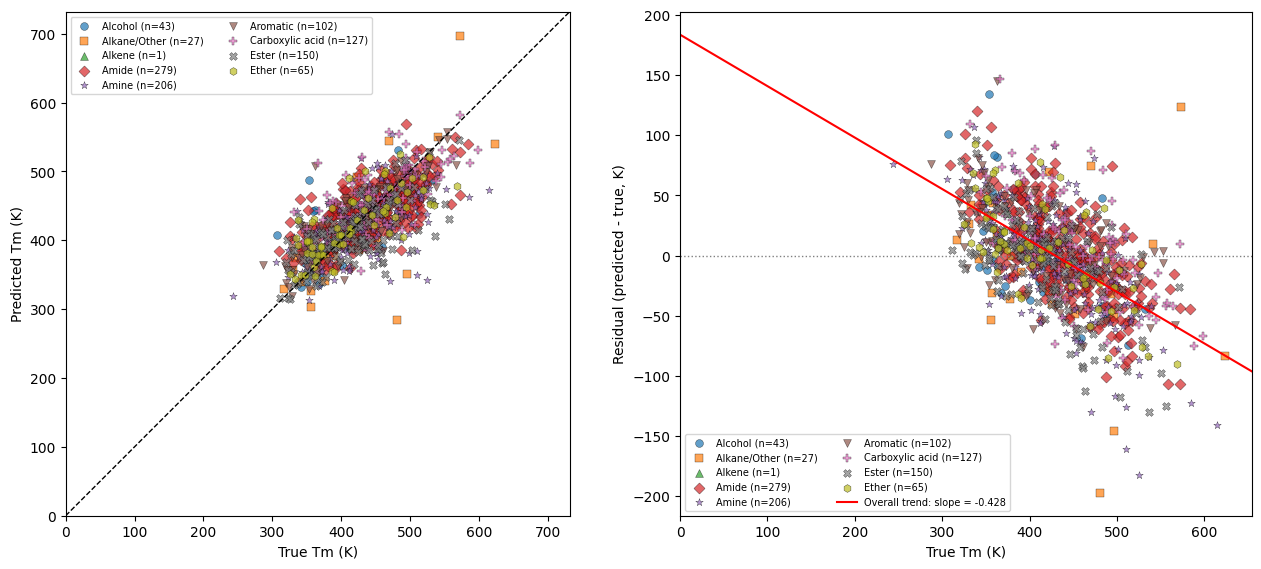

In [ ]:
#FUNCTIONAL GROUP CLASSES (EACH MOLECULE GETS THE FIRST MATCHING CLASS IN THIS ORDER, SO CLASSES DO NOT OVERLAP)
FUNCTIONAL_GROUPS = {
    "Carboxylic acid": "[CX3](=O)[OX2H1]",
    "Ester": "[#6][CX3](=O)[OX2H0][#6]",
    "Amide": "[CX3](=[OX1])[NX3]",
    "Amine": "[NX3;H2,H1,H0;!$(NC=O)]",
    "Alcohol": "[OX2H][CX4]",
    "Ether": "[OD2]([#6])[#6]",
    "Aromatic": "c1ccccc1",
    "Alkene": "[CX3]=[CX3]",
    "Alkyne": "[CX2]#[CX2]",
}
PATTERNS = {k: Chem.MolFromSmarts(v) for k, v in FUNCTIONAL_GROUPS.items()}   #COMPILED ONCE

def classify_molecule(smi):                                                #FIRST MATCHING CLASS, "Alkane/Other" IF NONE MATCH
    mol = Chem.MolFromSmiles(smi)
    if mol is None:
        return "Unknown"
    for name, patt in PATTERNS.items():
        if mol.HasSubstructMatch(patt):
            return name
    return "Alkane/Other"

pred["functional_class"] = pred["smiles"].apply(classify_molecule)
cls_tab = pred.groupby("functional_class").agg(n=("abs_error", "count"), mae=("abs_error", "mean"), median_ae=("abs_error", "median"),
                                               mean_residual=("residual", "mean")).sort_values("mae", ascending=False).round(3)
print(cls_tab)                                                           
print("\nPER-CLASS RESIDUAL TREND SLOPE:")
classes = sorted(pred["functional_class"].unique())
for c in classes:
    sub = pred[pred["functional_class"] == c]
    if len(sub) >= 5:
        print(f"  {c:16s} n={len(sub):4d}  slope={np.polyfit(sub['y_true'], sub['residual'], 1)[0]:+.3f}")
    else:
        print(f"  {c:16s} n={len(sub):4d}  (TOO FEW POINTS FOR A TREND)")

MARKERS = ["o", "s", "^", "D", "*", "v", "P", "X", "h", "<", ">"]         
COLOURS = plt.cm.tab10(np.linspace(0, 1, 10))
lim = max(pred["y_true"].max(), pred["y_pred"].max()) * 1.05
fig, axes = plt.subplots(1, 2, figsize=(13, 5.8))
for i, c in enumerate(classes):
    sub = pred[pred["functional_class"] == c]
    kw = dict(alpha=0.7, s=32, color=COLOURS[i % 10], marker=MARKERS[i % len(MARKERS)], edgecolor="black", linewidth=0.3, label=f"{c} (n={len(sub)})")
    axes[0].scatter(sub["y_true"], sub["y_pred"], **kw)
    axes[1].scatter(sub["y_true"], sub["residual"], **kw)
axes[0].plot([0, lim], [0, lim], "k--", linewidth=1)
axes[0].set_xlim(0, lim); axes[0].set_ylim(0, lim); axes[0].set_aspect("equal", adjustable="box")
axes[0].set_xlabel(f"True {NAME} ({UNIT})"); axes[0].set_ylabel(f"Predicted {NAME} ({UNIT})")
axes[1].axhline(0, color="gray", linestyle=":", linewidth=1)
axes[1].plot(tx, slope * tx + intercept, color="red", linewidth=1.5, label=f"Overall trend: slope = {slope:.3f}")
axes[1].set_xlim(0, tx[1]); axes[1].set_xlabel(f"True {NAME} ({UNIT})"); axes[1].set_ylabel(f"Residual (predicted - true, {UNIT})")
axes[0].legend(loc="upper left", fontsize=7, ncol=2); axes[1].legend(loc="lower left", fontsize=7, ncol=2)
plt.tight_layout(); plt.savefig(f"plots_{DS}_by_class.png", dpi=150); plt.show()

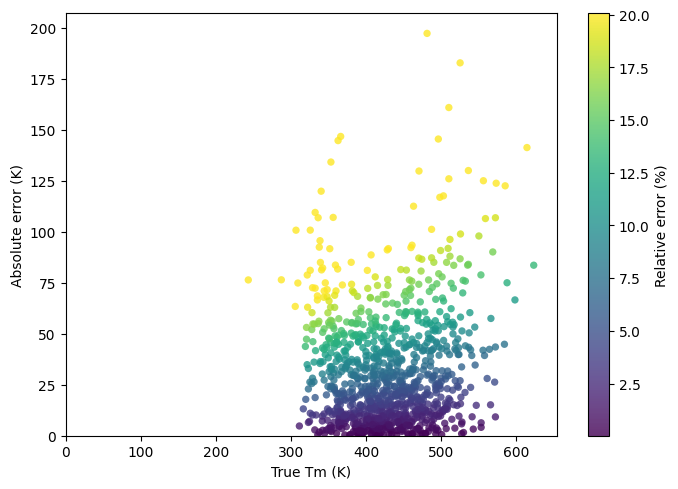

In [9]:
#ABSOLUTE ERROR VS TRUE VALUE, COLOURED BY RELATIVE ERROR
fig, ax = plt.subplots(figsize=(7, 5))
sc = ax.scatter(pred["y_true"], pred["abs_error"], c=pred["rel_error_pct"], cmap="viridis", s=28, alpha=0.8, edgecolor="none",
                vmax=pred["rel_error_pct"].quantile(0.95))                 #COLOUR SCALE CAPPED AT THE 95TH PERCENTILE
plt.colorbar(sc, ax=ax).set_label("Relative error (%)")
ax.set_xlim(0, pred["y_true"].max() * 1.05); ax.set_ylim(0, pred["abs_error"].max() * 1.05)
ax.set_xlabel(f"True {NAME} ({UNIT})"); ax.set_ylabel(f"Absolute error ({UNIT})")
plt.tight_layout(); plt.savefig(f"plots_{DS}_error_bubble.png", dpi=150); plt.show()

In [10]:
#ALL NUMBERS NEEDED FOR THE BASELINE SECTION OF THE REPORT, IN ONE PLACE
b1, b2 = CFG["bands"]
report = {
    "10-seed test MAE mean": seeds["test_mae"].mean(), "10-seed test MAE SD": seeds["test_mae"].std(),
    "10-seed test RMSE mean": seeds["test_rmse"].mean(), "10-seed test RMSE SD": seeds["test_rmse"].std(),
    "seed 0 test MAE": mae, "seed 0 test RMSE": rmse,
    "seed 0 median abs error": pred["abs_error"].median(),
    f"seed 0 % within {b1:g}": 100 * (pred["abs_error"] <= b1).mean(),
    f"seed 0 % within {b2:g}": 100 * (pred["abs_error"] <= b2).mean(),
    "seed 0 median relative error %": rel.median(),
    "seed 0 residual slope": slope, "seed 0 residual correlation": corr, "seed 0 mean residual": pred["residual"].mean(),
}
report = pd.Series(report).round(3)
print(report.to_string())
report.to_csv(f"{DS}_baseline_report_numbers.csv", header=["value"])

10-seed test MAE mean             32.665
10-seed test MAE SD                0.781
10-seed test RMSE mean            42.633
10-seed test RMSE SD               1.115
seed 0 test MAE                   32.039
seed 0 test RMSE                  42.430
seed 0 median abs error           24.419
seed 0 % within 25                50.400
seed 0 % within 50                78.600
seed 0 median relative error %     5.681
seed 0 residual slope             -0.428
seed 0 residual correlation       -0.588
seed 0 mean residual              -0.167
